Tugas 2 - Verifikasi Python (Bagian 4.1 - 4.5)

Jumlah Data uji: 90

Confusion matrix:
 [[40  8]
 [17 25]]
TP=25, TN=40, FP=8, FN=17

[Hitung Manual] Accuracy=0.722; Precision=0.758; Recall=0.595; F1=0.667
[Scikit-Learn]  Accuracy=0.722; Precision=0.758; Recall=0.595; F1=0.667


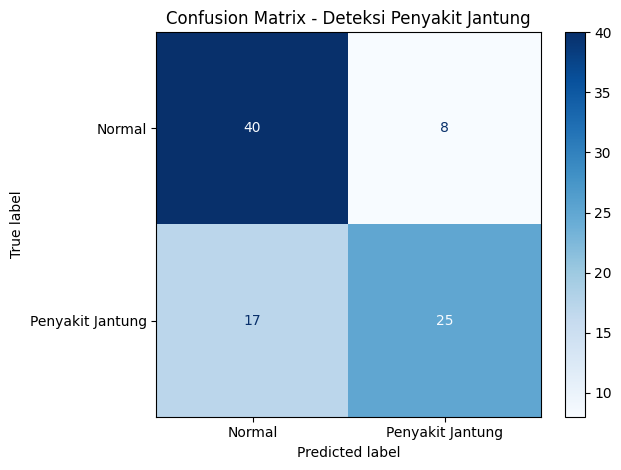

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Menyiapkan Dataset
df = pd.read_csv("Heart_Disease.csv")
df = df.dropna() # Menghapus baris dengan nilai kosong (missing values)

# Mengubah target 'num' menjadi biner: 0 = Normal, 1 = Penyakit Jantung (Fraud/Positif pada modul)
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns=['num'])

# 2. Membagi Data dan Melatih Model
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Jumlah Data uji:', len(y_test))

# 3. Menghitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('\nConfusion matrix:\n', cm)
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")

# 4. Perhitungan Manual dan Verifikasi
accuracy = (tp+tn) / (tp+tn+fp+fn)
precision = tp / (tp+fp) if (tp+fp) else 0
recall = tp / (tp+fn) if (tp+fn) else 0
f1 = 2 * precision * recall / (precision+recall) if (precision+recall) else 0

print(f"\n[Hitung Manual] Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}")

# Scikit-learn
print(f"[Scikit-Learn]  Accuracy={accuracy_score(y_test,y_pred):.3f}; Precision={precision_score(y_test,y_pred,zero_division=0):.3f}; Recall={recall_score(y_test,y_pred,zero_division=0):.3f}; F1={f1_score(y_test,y_pred,zero_division=0):.3f}")

# 5. Visualisasi Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Penyakit Jantung'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Deteksi Penyakit Jantung')
plt.tight_layout()
plt.show()

Tugas 3 - Evaluasi Data Tidak Seimbang (Bagian 4.7)

In [2]:
from sklearn.metrics import classification_report

# 1. Baseline Semua Normal
baseline = np.zeros(len(y_test), dtype=int)

print('--- Evaluasi Model Baseline ---')
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))

print('--- Evaluasi Model Decision Tree ---')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

--- Evaluasi Model Baseline ---
Baseline accuracy: 0.5333333333333333
              precision    recall  f1-score   support

           0       0.53      1.00      0.70        48
           1       0.00      0.00      0.00        42

    accuracy                           0.53        90
   macro avg       0.27      0.50      0.35        90
weighted avg       0.28      0.53      0.37        90

--- Evaluasi Model Decision Tree ---
              precision    recall  f1-score   support

           0       0.70      0.83      0.76        48
           1       0.76      0.60      0.67        42

    accuracy                           0.72        90
   macro avg       0.73      0.71      0.71        90
weighted avg       0.73      0.72      0.72        90



Tugas 4 - Eksperimen Threshold & Rekomendasi (Bagian 4.8)

In [3]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

print(f"{'Threshold':<10} | {'Precision':<10} | {'Recall':<10}")
print("-" * 35)
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    prec = round(precision_score(y_test, pred, zero_division=0), 3)
    rec = round(recall_score(y_test, pred, zero_division=0), 3)
    print(f"{threshold:<10} | {prec:<10} | {rec:<10}")

Threshold  | Precision  | Recall    
-----------------------------------
0.2        | 0.642      | 0.81      
0.4        | 0.743      | 0.619     
0.5        | 0.758      | 0.595     
0.7        | 0.758      | 0.595     
